# 04 · Listening data and the interaction matrix

## Why the playlists are simulated
The catalog has no users. Real playlist logs (Spotify's Million Playlist Dataset) need a gated
sign-up and are 33 GB, so the pipeline simulates listeners, and **every collaborative-filtering
result in this project is a result on simulated behaviour.** Swap in real `pid, track_uri` rows and
everything downstream runs unchanged.

The original notebooks chunked each genre into popularity-sorted playlists of ~335 tracks and then
added every popular track to 15 **random** playlists. Random edges are noise, so the CF model
had nothing to learn: its test AUC was 0.535 and precision@10 was 0.004.

`src/data/simulate.py` instead gives each simulated listener a taste with the structure real data has:

| ingredient | what it models | visible to content features? |
|---|---|---|
| home genre + 0-2 neighbouring genres (from the learned genre map) | scenes | yes |
| fixed crossover partners per genre (e.g. a set of *metal* listeners who also play *opera*) | habits that cut across sound | **no** |
| a preferred point in audio space near the home genre | sound preference | yes |
| popularity appetite (hits ↔ deep cuts) | mainstreamness | partly |
| 8 hidden taste factors shared by each artist's tracks | lyrics, era, scene, fandom | **no** |
| artist loyalty: 25% of picks are another song by an artist already on the list | fandom | **no** |
| 3% off-taste discoveries | noise | no |

Part of each playlist is explainable from audio and genre and part only from co-listening, which
is the setting where content, CF and a hybrid can be compared fairly.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)
from src.data.load import load_catalog
from src.data.simulate import simulate_playlists
from src import artifacts
tracks = load_catalog()
feats = artifacts.load_features()
inter, meta = simulate_playlists(tracks, feats["audio"], feats["genre_sim"])
print(f"{meta.shape[0]:,} playlists, {len(inter):,} playlist-track rows, {inter.track_uri.nunique():,} distinct tracks used")
meta.head()

6,000 playlists, 234,992 playlist-track rows, 22,456 distinct tracks used


,pid,playlist_name,home_genre,taste_genres,pop_appetite,n_tracks
0,0,Comedy & Funk Mix #0,comedy,comedy;funk;forro,1.86,19
1,1,K-Pop Mix #1,k-pop,k-pop,0.89,12
2,2,Singer Songwriter & Acoustic Mix #2,singer-songwriter,singer-songwriter;acoustic;iranian,0.33,16
3,3,Emo Mix #3,emo,emo,0.95,67
4,4,Opera Mix #4,opera,opera,1.61,28


In [2]:
for pid in [0, 3]:
    p = meta.iloc[pid]
    print(f"\n{p.playlist_name}  |  taste: {p.taste_genres}  |  popularity appetite {p.pop_appetite}")
    display(inter[inter.pid == pid][["track_name", "artists", "primary_genre", "popularity"]].head(8))


Comedy & Funk Mix #0  |  taste: comedy;funk;forro  |  popularity appetite 1.86


,track_name,artists,primary_genre,popularity
0,La Carta,NAFTA,funk,48
1,Crazy Rap (Colt 45 & 2 Zig Zags),Afroman,comedy,74
2,Nothing's Gonna Change My Love for You,George Benson,guitar,71
3,Life on the Road,Josh Sneed,comedy,27
4,Paixão Proibida,Tayrone Cigano,forro,46
5,Festa de Maloka,Gabb MC;Caio Passos;Igão;Love Funk;Mc Kadu;MC ...,funk,55
6,Rodada de Shot - Ao Vivo,Israel Novaes;Paulo Pires,forro,47
7,Volte Amor,Tayrone Cigano,forro,50



Emo Mix #3  |  taste: emo  |  popularity appetite 0.95


,track_name,artists,primary_genre,popularity
47,Huésped en casa propia,PXNDX,punk-rock,44
48,Si Supieras,PXNDX,punk-rock,47
49,haunt me (x 3),Teen Suicide,emo,72
50,Vandalize,ONE OK ROCK,j-rock,58
51,What You Make It,With Confidence,emo,67
52,vice city,XXXTENTACION,emo,72
53,YuNg BrAtZ,XXXTENTACION,emo,76
54,Hate Me,Lil Peep,emo,60


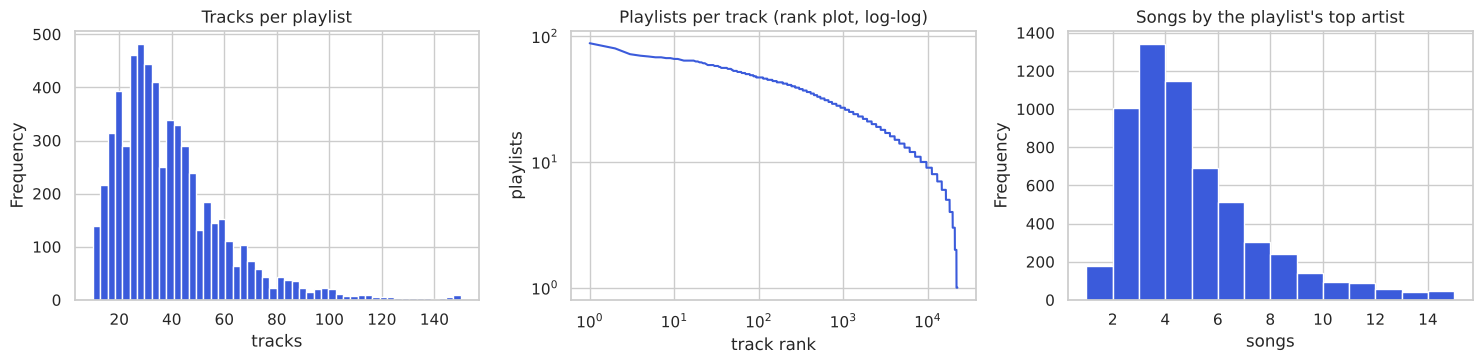

{'count': 6000.0, 'mean': 39.2, 'std': 21.2, 'min': 10.0, '25%': 24.0, '50%': 34.0, '75%': 48.0, 'max': 150.0}
{'count': 22456.0, 'mean': 10.5, 'std': 8.0, 'min': 1.0, '25%': 5.0, '50%': 8.0, '75%': 13.0, 'max': 88.0}


In [3]:
per_pl = inter.groupby("pid").size()
per_tr = inter.groupby("track_uri").size()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
per_pl.plot.hist(bins=50, ax=axes[0], color="#3b5bdb"); axes[0].set(title="Tracks per playlist", xlabel="tracks")
srt = np.sort(per_tr.values)[::-1]
axes[1].loglog(np.arange(1, len(srt) + 1), srt, color="#3b5bdb"); axes[1].set(title="Playlists per track (rank plot, log-log)", xlabel="track rank", ylabel="playlists")
art = inter.groupby("pid").artists.apply(lambda a: a.value_counts().iloc[0])
art.plot.hist(bins=range(1, 16), ax=axes[2], color="#3b5bdb"); axes[2].set(title="Songs by the playlist's top artist", xlabel="songs")
plt.tight_layout(); plt.savefig(FIG / "04_interactions.png"); plt.show()
print(per_pl.describe().round(1).to_dict()); print(per_tr.describe().round(1).to_dict())

Playlist lengths are log-normal around 35 tracks (real playlists look like this; the original had
a flat ~335), track usage has the long-tail shape of real listening data, and artist loyalty
shows up as playlists holding several songs by one artist.

## Interaction matrix
Columns follow the catalog order, so content and CF scores line up and tracks nobody has added yet still have a column.

In [4]:
from src.features.interaction_matrix import InteractionMatrixBuilder, make_splits, save_splits
builder = InteractionMatrixBuilder(tracks.track_uri.tolist())
M = builder.build(inter)
print("shape (playlists x tracks):", M.shape, " nnz:", M.nnz, f" density: {M.nnz / np.prod(M.shape):.4%}")
print("tracks never added to any playlist:", int((np.asarray(M.sum(0)).ravel() == 0).sum()))

shape (playlists x tracks): (6000, 22800)  nnz: 234992  density: 0.1718%
tracks never added to any playlist: 344


## Evaluation splits

The original used LightFM's global random split, which can leave a playlist with nothing in
training and mixes the "new track" problem into the warm test. Here there are three settings:

* **warm** - each playlist's tracks split 70 / 10 / 20 into train / validation / test;
* **new releases** - 8% of the catalog is hidden from training entirely; every playlist edge to those
  tracks is a test target, ranked among the new releases only;
* **short playlists** - (notebook 05) only 3 training tracks per playlist are visible, like a listener
  who just started a playlist.

Validation is only used for tuning; test is only used once, in notebook 07.

In [5]:
splits = make_splits(M)
for k in ("train", "val", "test", "cold_test"):
    print(f"{k:>10}: {splits[k].nnz:>7,} edges, {int((np.diff(splits[k].indptr) > 0).sum()):,} playlists")
print(f"new-release tracks: {len(splits['cold_items']):,}")
assert splits["train"][:, splits["cold_items"]].nnz == 0, "cold tracks leaked into training"
assert (splits["train"].multiply(splits["test"])).nnz == 0

     train: 151,152 edges, 6,000 playlists
       val:  21,620 edges, 6,000 playlists
      test:  43,169 edges, 6,000 playlists
 cold_test:  19,051 edges, 5,460 playlists
new-release tracks: 1,824


In [6]:
inter.to_csv(config.INTERACTIONS, index=False)
meta.to_csv(config.PLAYLISTS, index=False)
save_splits(config.SPLITS, splits)
print("saved interactions, playlists and splits")

saved interactions, playlists and splits
